# Industrial equipment failure detection

Explore the **synthetic UCI AI4I 2020** data and review the reproducible experiment. Run `python train.py` from the project root first. This notebook does not tune against the test set. Dataset: https://doi.org/10.24432/C5HS5C (CC BY 4.0).

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd() if (Path.cwd() / 'data').exists() else Path.cwd().parent
data = pd.read_csv(ROOT / 'data/ai4i2020.csv')
print('Shape:', data.shape)
print('Missing values:', int(data.isna().sum().sum()))
print(data.head().to_string(index=False))

Matplotlib is building the font cache; this may take a moment.


Shape: (10000, 14)
Missing values: 0
 UDI Product ID Type  Air temperature [K]  Process temperature [K]  Rotational speed [rpm]  Torque [Nm]  Tool wear [min]  Machine failure  TWF  HDF  PWF  OSF  RNF
   1     M14860    M                298.1                    308.6                    1551         42.8                0                0    0    0    0    0    0
   2     L47181    L                298.2                    308.7                    1408         46.3                3                0    0    0    0    0    0
   3     L47182    L                298.1                    308.5                    1498         49.4                5                0    0    0    0    0    0
   4     L47183    L                298.2                    308.6                    1433         39.5                7                0    0    0    0    0    0
   5     L47184    L                298.2                    308.7                    1408         40.0                9                0    0    0 

## Class imbalance
Accuracy can look high while missing every failure. Report failure precision and recall, plus average precision.

Machine failure
No failure    9661
Failure        339
Name: count, dtype: int64
Failure prevalence: 3.39%


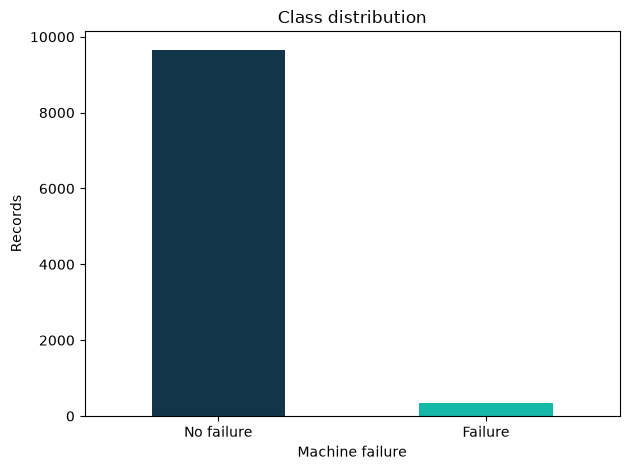

In [2]:
print(data['Machine failure'].value_counts().rename(index={0:'No failure',1:'Failure'}))
print(f"Failure prevalence: {data['Machine failure'].mean():.2%}")
data['Machine failure'].value_counts().sort_index().plot.bar(title='Class distribution', color=['#12354a','#14b8a6'])
plt.xticks([0,1], ['No failure','Failure'], rotation=0)
plt.ylabel('Records')
plt.tight_layout()
plt.show()

## Features and data leakage
Only the six listed inputs are allowed. Identifiers and failure-mode outcomes must never enter the model.

         Type  Air temperature [K]  Process temperature [K]  Rotational speed [rpm]   Torque [Nm]  Tool wear [min]
count   10000         10000.000000             10000.000000            10000.000000  10000.000000     10000.000000
unique      3                  NaN                      NaN                     NaN           NaN              NaN
top         L                  NaN                      NaN                     NaN           NaN              NaN
freq     6000                  NaN                      NaN                     NaN           NaN              NaN
mean      NaN           300.004930               310.005560             1538.776100     39.986910       107.951000
std       NaN             2.000259                 1.483734              179.284096      9.968934        63.654147
min       NaN           295.300000               305.700000             1168.000000      3.800000         0.000000
25%       NaN           298.300000               308.800000             1423.000

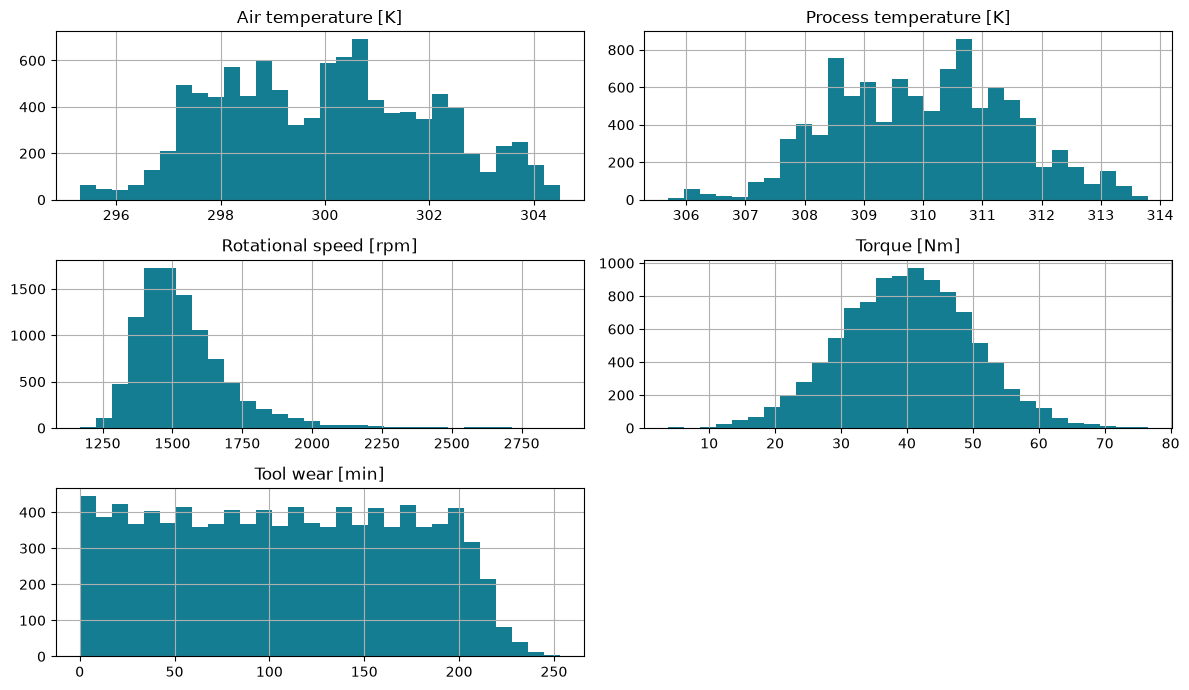

In [3]:
features = ['Type','Air temperature [K]','Process temperature [K]','Rotational speed [rpm]','Torque [Nm]','Tool wear [min]']
print(data[features].describe(include='all').to_string())
data[features[1:]].hist(figsize=(12,7), bins=30, color='#147d92')
plt.tight_layout()
plt.show()

## Experiment protocol
`train.py` fits preprocessing and classifiers on 6,000 training rows, chooses thresholds and the model on 2,000 validation rows, and then reports the untouched 2,000-row test set. Selection maximizes validation F2, which favors recall. The model is not refitted afterward.

Selected: Random forest
Threshold: 0.21
                    accuracy precision    recall        f1        f2 average_precision
Dummy baseline         0.966       0.0       0.0       0.0       0.0             0.034
Logistic regression   0.9485  0.347826  0.588235  0.437158  0.516796          0.408677
Decision tree         0.9725  0.582278  0.676471   0.62585  0.655271          0.610875
Random forest         0.9675  0.513514  0.838235  0.636872  0.744125          0.689378


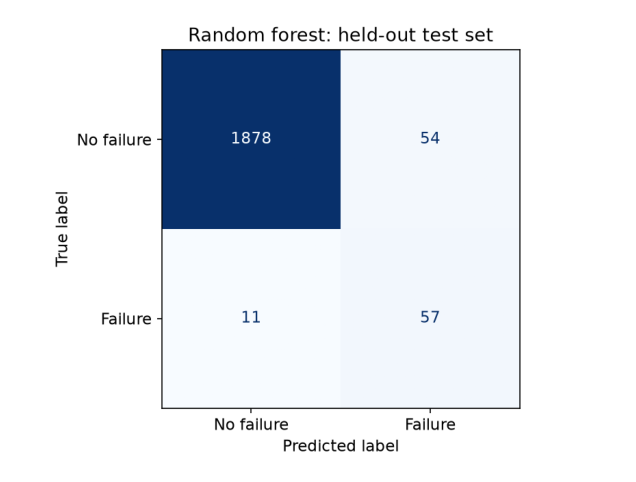

In [4]:
metrics = json.loads((ROOT / 'reports/metrics.json').read_text())
print('Selected:', metrics['selected_model'])
print('Threshold:', metrics['threshold'])
print(pd.DataFrame(metrics['test']).T[['accuracy','precision','recall','f1','f2','average_precision']].to_string())
image = plt.imread(ROOT / 'reports/confusion_matrix.png')
plt.figure(figsize=(8,6))
plt.imshow(image)
plt.axis('off')
plt.show()

## Missed failures
These records are for final error analysis, not further tuning on the same test set. Failure indicators below are outcomes, never model features.

In [5]:
misses = pd.read_csv(ROOT / 'reports/false_negatives.csv')
print(misses.to_string(index=False))
print('Missed failure-mode counts (may overlap):', metrics['false_negative_modes'])

 UDI Product ID Type  Air temperature [K]  Process temperature [K]  Rotational speed [rpm]  Torque [Nm]  Tool wear [min]  Machine failure  TWF  HDF  PWF  OSF  RNF  failure_score  prediction
6257     L53436    L                301.0                    310.6                    1493         37.8              206                1    1    0    0    0    0       0.058808           0
1493     M16352    M                298.0                    308.7                    1479         58.5              176                1    0    0    1    0    0       0.087341           0
7088     L54267    L                300.6                    310.3                    1648         30.5              217                1    1    0    0    0    0       0.061189           0
4045     M18904    M                301.9                    310.9                    1419         47.7               20                1    0    0    0    0    0       0.005570           0
2167     M17026    M                299.6         

## Interpretation and next steps
The data are synthetic and sequentially correlated. Random-split performance does not establish real-factory generalization. Scores are uncalibrated. Future experiments need a new holdout, chronological or machine-held-out splits, calibrated scores and real labeled sensor histories. The app predicts a snapshot failure label, not time until failure.